In [1]:
bac = 'aeruginosa'

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, roc_auc_score, confusion_matrix, matthews_corrcoef
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import h5py
import os
import math
import copy
import time
from sklearn.preprocessing import StandardScaler # 导入StandardScaler

import math
import torch
from torch import nn

class Expert_TEXTCNN(nn.Module):
    """用于MoE的专家模块（支持序列长度100）"""
    def __init__(self, embedding_size, dropout, num_heads, max_pool=5):
        super(Expert_TEXTCNN, self).__init__()
        
        # 配置参数
        self.embedding_size = embedding_size
        self.dropout = dropout
        self.num_heads = num_heads
        self.max_pool = max_pool
        self.seq_len = 100  # 固定序列长度为100
        
        # 计算CNN输出尺寸（基于序列长度100）
        if max_pool == 2:
            shape = 12416
        elif max_pool == 3:
            shape = 8256
        elif max_pool == 4:
            shape = 6144
        elif max_pool == 5:
            shape = 4864
        else:  # 默认值
            shape = 4096
        
        # 嵌入层和位置编码
        self.pos_encoding = PositionalEncoding(num_hiddens=self.embedding_size, 
                                              dropout=self.dropout,
                                              max_len=self.seq_len)  # 设置最大长度
        
        # 卷积层组
        self.conv1 = nn.Conv1d(in_channels=self.embedding_size, out_channels=64, kernel_size=2, stride=1)
        self.conv2 = nn.Conv1d(in_channels=self.embedding_size, out_channels=64, kernel_size=3, stride=1)
        self.conv3 = nn.Conv1d(in_channels=self.embedding_size, out_channels=64, kernel_size=4, stride=1)
        self.conv4 = nn.Conv1d(in_channels=self.embedding_size, out_channels=64, kernel_size=5, stride=1)
        self.MaxPool1d = nn.MaxPool1d(kernel_size=self.max_pool)
        
        # 注意力机制
        self.attention_encode = AttentionEncode(self.dropout, self.embedding_size, self.num_heads)
        
        # 特征增强网络
        self.fan = FAN_encode(self.dropout, shape)
        self.dropout_layer = nn.Dropout(self.dropout)

        #全连接神经网络 
        self.full1 = nn.Linear(shape, 1024)
        self.full2 = nn.Linear(1024, 512)
        self.full3 = nn.Linear(512, 256)
        
    def TextCNN(self, x):
        """多尺度卷积特征提取"""
        x1 = nn.LeakyReLU()(self.conv1(x))
        x1 = self.MaxPool1d(x1)
        x2 = nn.LeakyReLU()(self.conv2(x))
        x2 = self.MaxPool1d(x2)
        x3 = nn.LeakyReLU()(self.conv3(x))
        x3 = self.MaxPool1d(x3)
        x4 = nn.LeakyReLU()(self.conv4(x))
        x4 = self.MaxPool1d(x4)
        
        # 多尺度特征融合
        y = torch.cat([x1, x2, x3, x4], dim=-1)
        y = self.dropout_layer(y)
        flat_y = y.view(y.size(0), -1)
        
        return flat_y

    def forward(self, train_data):
        # 位置编码
        scaled_embed = train_data * math.sqrt(self.embedding_size)
        pos_output = self.pos_encoding(scaled_embed)
        # 注意力编码
        attention_output = self.attention_encode(pos_output)
        # 残差连接
        vectors = train_data + attention_output
        # 调整维度用于卷积 (batch, channels, seq_len)
        cnn_input = vectors.permute(0, 2, 1)
        # CNN特征提取
        cnn_output = self.TextCNN(cnn_input)
        # FAN特征增强
        fan_output = self.fan(cnn_output)
        # 全连接层
        logit1 = self.full1(fan_output)
        logit1 = torch.nn.LeakyReLU()(logit1)
        logit2 = self.full2(logit1)
        logit2 = torch.nn.LeakyReLU()(logit2)
        out_logit = self.full3(logit2)
        
        return out_logit  


# ================== 辅助模块（更新支持序列长度100）================== 
class PositionalEncoding(nn.Module):
    def __init__(self, num_hiddens, dropout, max_len=1000):
        super(PositionalEncoding, self).__init__()
        self.dropout = nn.Dropout(dropout)
        # 创建位置编码矩阵
        self.P = torch.zeros((1, max_len, num_hiddens))
        X = torch.arange(max_len, dtype=torch.float32).reshape(-1, 1) / torch.pow(
            10000, torch.arange(0, num_hiddens, 2, dtype=torch.float32) / num_hiddens)
        self.P[:, :, 0::2] = torch.sin(X)
        self.P[:, :, 1::2] = torch.cos(X)

    def forward(self, X):
        # 只取前max_len个位置
        X = X + self.P[:, :X.shape[1], :].to(X.device)
        return self.dropout(X)

class AddNorm(nn.Module):
    def __init__(self, normalized_shape, dropout):
        super(AddNorm, self).__init__()
        self.dropout = nn.Dropout(dropout)
        self.ln = nn.LayerNorm(normalized_shape)

    def forward(self, X, Y):
        return self.ln(self.dropout(Y) + X)

class PositionWiseFFN(nn.Module):
    def __init__(self, ffn_num_input, ffn_num_hiddens, ffn_num_outputs):
        super(PositionWiseFFN, self).__init__()
        self.dense1 = nn.Linear(ffn_num_input, ffn_num_hiddens)
        self.leakyrelu = nn.LeakyReLU()
        self.dense2 = nn.Linear(ffn_num_hiddens, ffn_num_outputs)

    def forward(self, X):
        return self.dense2(self.leakyrelu(self.dense1(X)))

class AttentionEncode(nn.Module):
    def __init__(self, dropout, embedding_size, num_heads):
        super(AttentionEncode, self).__init__()
        self.attention = nn.MultiheadAttention(
            embed_dim=embedding_size,
            num_heads=num_heads,
            dropout=0.3,
            batch_first=True
        )
        self.add_norm = AddNorm(normalized_shape=embedding_size, dropout=dropout)

    def forward(self, X):
        attn_output, _ = self.attention(X, X, X)
        return self.add_norm(X, attn_output)

class FAN_encode(nn.Module):
    def __init__(self, dropout, shape):
        super(FAN_encode, self).__init__()
        self.add_norm = AddNorm(normalized_shape=shape, dropout=dropout)
        self.ffn = PositionWiseFFN(
            ffn_num_input=shape,
            ffn_num_hiddens=2*shape,
            ffn_num_outputs=shape
        )

    def forward(self, X):
        return self.add_norm(X, self.ffn(X))

import torch
import torch.nn as nn
import torch.nn.functional as F

class Expert_ESM(nn.Module):
    def __init__(self, input_dim=960, hidden_dim=256, output_dim=256, num_layers=1, dropout_rate=0.3):
        """
        ESM嵌入专家模块 (BiLSTM + 自注意力)
        """
        super(Expert_ESM, self).__init__()
        
        # 双向LSTM处理序列
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True
        )
        
        # 自注意力机制
        self.attention = nn.Sequential(
            nn.Linear(2 * hidden_dim, 128),  # 双向输出拼接
            nn.Tanh(),
            nn.Linear(128, 1),
            nn.Softmax(dim=1)
        )
        
        # 输出投影层
        self.projection = nn.Linear(2 * hidden_dim, output_dim)
        
        # 层归一化
        self.layer_norm = nn.LayerNorm(output_dim)
        self.dropout = nn.Dropout(dropout_rate)

    def forward(self, x):
        # LSTM处理序列
        lstm_out, _ = self.lstm(x)
        lstm_out = self.dropout(lstm_out)
        # 计算自注意力权重
        attn_scores = self.attention(lstm_out)
        # 加权平均池化
        context_vector = torch.sum(attn_scores * lstm_out, dim=1)
        context_vector = self.dropout(context_vector)
        # 投影到目标维度
        projected = self.projection(context_vector)   
        # 层归一化输出
        output = self.layer_norm(projected)
        
        return output

import torch
import torch.nn as nn

class Expert_MACREL(nn.Module):
    def __init__(self, input_dim=25, hidden_dims=[128, 256], output_dim=256, dropout_rate=0.3):
        """
        物理化学性质专家模块
        """
        super().__init__()
        
        # 构建隐藏层
        layers = []
        prev_dim = input_dim
        
        for i, hidden_dim in enumerate(hidden_dims):
            layers.append(nn.Linear(prev_dim, hidden_dim))
            layers.append(nn.LayerNorm(hidden_dim))
            layers.append(nn.LeakyReLU(negative_slope=0.01))
            layers.append(nn.Dropout(dropout_rate))
            prev_dim = hidden_dim
            
        self.hidden_layers = nn.Sequential(*layers)
        self.output_layer = nn.Linear(prev_dim, output_dim)

    def forward(self, x):
        # 通过隐藏层
        for i, layer in enumerate(self.hidden_layers):
            x = layer(x)
            
        output = self.output_layer(x)
        
        return output

import torch
import torch.nn as nn
import torch.nn.functional as F
import copy 
import time

#def contrastive_loss(z1, z2, temperature=0.1):
#    """InfoNCE对比损失"""
#    z1 = F.normalize(z1, dim=1)
#    z2 = F.normalize(z2, dim=1)
#    logits = torch.mm(z1, z2.T) / temperature
#    labels = torch.arange(z1.size(0)).to(z1.device)
#    return F.cross_entropy(logits, labels)
#
#def symmetric_contrastive_loss(z1, z2, temperature=0.1):
#    loss_1_2 = contrastive_loss(z1, z2, temperature)
#    loss_2_1 = contrastive_loss(z2, z1, temperature)
#    return (loss_1_2 + loss_2_1) / 2

class ProjectionHead(nn.Module):
    """一个简单的非线性投影头"""
    def __init__(self, input_dim, hidden_dim=256, output_dim=128):
        super().__init__()
        self.head = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(inplace=True),
            nn.Linear(hidden_dim, output_dim)
        )
    
    def forward(self, x):
        return self.head(x)

class SoftMoE(nn.Module):
    """支持异构输入的Soft MoE结构"""
    def __init__(self, input_dims, hidden_dims_dict, output_dim, dropout_rate=0.3):
        super().__init__()
        self.num_experts = 3  # MACREL, TEXTCNN, ESM

        # TextCNN 嵌入层
        vocab_size = hidden_dims_dict["TEXTCNN"][0]
        embedding_dim = hidden_dims_dict["TEXTCNN"][1]
        self.textcnn_embedding = nn.Embedding(vocab_size, embedding_dim)
        
        # 专家模块
        self.experts = nn.ModuleList([
            Expert_MACREL(input_dims[0], hidden_dims_dict["MACREL"], output_dim, dropout_rate),
            Expert_TEXTCNN(
                embedding_size=embedding_dim,
                dropout=dropout_rate,
                num_heads=hidden_dims_dict["TEXTCNN"][2],
                max_pool=hidden_dims_dict["TEXTCNN"][3]
            ),
            Expert_ESM(input_dims[2], hidden_dims_dict["ESM"], output_dim, 1, dropout_rate)
        ])
        
        # 统一门控网络
        total_gate_input_dim = (
            input_dims[0]  # MACREL特征维度
            + embedding_dim  # TextCNN嵌入均值
            + input_dims[2]  # ESM嵌入均值
        )
        self.gate_network = nn.Sequential(
            nn.Linear(total_gate_input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, self.num_experts)
        )
        
        self.softmax = nn.Softmax(dim=1)
        self.dropout = nn.Dropout(dropout_rate)

    def forward(self, x_list):
        # 计算各专家的门控分数        
        gate_scores = []
        
        # 专家输入处理
        macrel_x = x_list[0]  # [batch, macrel_dim]
        textcnn_x = x_list[1].long()  # [batch, seq_len]
        esm_x = x_list[2]  # [batch, seq_len, esm_dim]
        
        # TextCNN嵌入
        embedded_textcnn = self.textcnn_embedding(textcnn_x)  # [batch, seq_len, embed_dim]
        # TextCNN 和 ESM 均值池化
        mean_textcnn = embedded_textcnn.mean(dim=1)  # [batch, embed_dim]
        mean_esm = esm_x.mean(dim=1)  # [batch, esm_dim]

        # 拼接成统一门控输入
        gate_input = torch.cat([macrel_x, mean_textcnn, mean_esm], dim=1)  # [batch, total_dim]

        # 计算门控分数
        gate_scores = self.gate_network(gate_input)  # [batch, num_experts]
        gate_scores = self.softmax(gate_scores)  # [batch, num_experts]

        # 各专家原始输出
        expert_outputs = []
        for i, expert in enumerate(self.experts):
            if i == 1:  # TextCNN专家：用嵌入后的输入
                expert_input = embedded_textcnn
            else:
                expert_input = x_list[i]
            expert_outputs.append(expert(expert_input))
        expert_outputs = torch.stack(expert_outputs, dim=1)  # [batch, num_experts, output_dim]
        
        # MoE输出 - 加权平均
        moe_output = torch.sum(expert_outputs * gate_scores.unsqueeze(-1), dim=1) # [batch, output_dim]
        
        return self.dropout(moe_output), gate_scores, expert_outputs

from pytorch_metric_learning.losses import SupConLoss

class ProteinClassifier(nn.Module):
    def __init__(self, input_dims, hidden_dims_dict, output_dim, num_classes, 
                 contrast_weight=0.01, lr=1e-4, dropout_rate=0.3):
        super().__init__()
        self.contrast_weight = contrast_weight
        
        # MoE模块
        self.moe = SoftMoE(input_dims, hidden_dims_dict, output_dim, dropout_rate)

        # --- 新增：为每个专家的输出创建一个投影头 ---
        self.macrel_proj_head = ProjectionHead(input_dim=output_dim, output_dim=128)
        self.textcnn_proj_head = ProjectionHead(input_dim=output_dim, output_dim=128)
        self.esm_proj_head = ProjectionHead(input_dim=output_dim, output_dim=128)
        
        # 分类器
        #self.classifier = nn.Linear(output_dim, num_classes)

                # --- 增强的分类器 (MLP Head) ---
        self.classifier = nn.Sequential(
            nn.Linear(output_dim, output_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(output_dim // 2, num_classes)
        )
        
        self.criterion = nn.CrossEntropyLoss()
        self.supcon_loss = SupConLoss(temperature=0.07)   # 可以调节 temperature
        self.optimizer = torch.optim.Adam(self.parameters(), lr=lr)

    def forward(self, x_list):
        # 获取MoE输出及各专家特征
        moe_output, gate_scores, expert_outputs = self.moe(x_list)
        return self.classifier(moe_output), moe_output, gate_scores, expert_outputs

    def compute_loss(self, logits, expert_outputs, labels):
        """计算组合损失（分类损失 + 对比损失）"""
        # 分类损失 (和以前一样)
        cls_loss = self.criterion(logits, labels)
        
        # 解包专家输出 (h)
        h_macrel = expert_outputs[:, 0, :]
        h_textcnn = expert_outputs[:, 1, :]
        h_esm = expert_outputs[:, 2, :]
        
        # 将专家输出通过各自的投影头，得到用于对比的表征 (z)
        z_macrel = self.macrel_proj_head(h_macrel)
        z_textcnn = self.textcnn_proj_head(h_textcnn)
        z_esm = self.esm_proj_head(h_esm)
        
        ## 在投影后的表征 z 上进行对比学习
        #loss_macrel_textcnn = symmetric_contrastive_loss(z_macrel, z_textcnn)
        #loss_macrel_esm = symmetric_contrastive_loss(z_macrel, z_esm)
        #loss_textcnn_esm = symmetric_contrastive_loss(z_textcnn, z_esm)
        #contrast_loss = (loss_macrel_textcnn + loss_macrel_esm + loss_textcnn_esm) / 3
        
        # 沿样本维度合并多视图特征
        z_all = torch.cat([z_macrel, z_textcnn, z_esm], dim=0)
        
        # 应地复制标签
        labels_all = labels.repeat(3)
        
        # 计算 SupConLoss
        contrast_loss = self.supcon_loss(z_all, labels_all)
        
        # 总损失
        total_loss = cls_loss + self.contrast_weight * contrast_loss
        return total_loss, cls_loss, contrast_loss


    def train_model(self, train_loader, val_loader, epochs=150, device="cuda"):
        self.to(device)   
        best_Precision = 0
        best_Sensitivity = 0
        best_model = None

        for epoch in range(epochs):
            start_time = time.time()
            # 训练阶段
            self.train()
            total_loss = 0.0
            total_cls_loss = 0.0
            total_con_loss = 0.0
            y_true_train, y_pred_train, y_prob_train = [], [], []

            for X_list, y in train_loader:
                X_list = [x.to(device, non_blocking=True) for x in X_list]
                y = y.to(device, non_blocking=True)
                    
                self.optimizer.zero_grad()
                logits, _, _, expert_outputs = self(X_list)
                loss, cls_loss, con_loss = self.compute_loss(logits, expert_outputs, y)
                loss.backward()
                self.optimizer.step()
                
                total_loss += loss.item()
                total_cls_loss += cls_loss.item()
                total_con_loss += con_loss.item()
                # 收集预测结果
                y_true_train.extend(y.cpu().numpy())
                y_pred_train.extend(torch.argmax(logits, dim=1).cpu().numpy())
                y_prob_train.extend(torch.softmax(logits, dim=1)[:, 1].cpu().detach().numpy()) 

            # 验证阶段
            self.eval()
            y_true_val, y_pred_val, y_prob_val = [], [], []
            with torch.no_grad():
                for X_list, y in val_loader:
                    X_list = [x.to(device, non_blocking=True) for x in X_list]
                    y = y.to(device, non_blocking=True)
                    
                    logits, _, _, _ = self(X_list)
                    y_true_val.extend(y.cpu().numpy())
                    y_pred_val.extend(torch.argmax(logits, dim=1).cpu().numpy())
                    y_prob_val.extend(torch.softmax(logits, dim=1)[:, 1].cpu().numpy())
            
            # 计算指标
            train_metrics = compute_metrics(y_true_train, y_pred_train, y_prob_train)
            val_metrics = compute_metrics(y_true_val, y_pred_val, y_prob_val)
            print(f"一个epoch耗时: {time.time() - start_time:.4f}秒")
            
            # 每10个epoch打印一次
            if (epoch + 1) % 10 == 0:
                print(f"Epoch {epoch+1}/{epochs}")
                print(f"  Train Loss: {total_loss:.4f} "
                      f"[CLS: {total_cls_loss:.4f} CON: {total_con_loss:.4f}]")
                print(f"  Train Metrics: {train_metrics}")
                print(f"  Validation Metrics: {val_metrics}")

            # 保存最优模型
            if val_metrics["Precision"]+val_metrics["Sensitivity"] > best_Precision+best_Sensitivity:
                best_Precision = val_metrics["Precision"]
                best_Sensitivity = val_metrics["Sensitivity"]
                best_model = copy.deepcopy(self.state_dict())
                best_metrics = val_metrics

        # 加载最佳模型
        if best_model is not None:
            self.load_state_dict(best_model)
        return self, best_metrics

class TupleDataset(torch.utils.data.Dataset):
    def __init__(self, X_list, y):
        self.X_list = X_list
        self.y = y

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return [X[idx] for X in self.X_list], self.y[idx]

class TupleTestDataset(torch.utils.data.Dataset):
    def __init__(self, X_list):
        self.X_list = X_list

    def __len__(self):
        return len(self.X_list[0])  # 假设每个特征维度的样本数一致

    def __getitem__(self, idx):
        return [X[idx] for X in self.X_list]

# ==================== 原始函数和类定义 ====================

# 标签生成 (此处预测无需标签，但保留函数定义以保持完整性)
def load_data(file):
    """
    从 CSV 文件加载数据，根据文件名分配标签。
    - 阳性样本（AMPs）：文件名不包含 "nonAMP"
    - 阴性样本（nonAMP）：文件名包含 "nonAMP"
    """
    data = pd.read_csv(file, index_col=0)  # 加载 CSV 文件
    label = 0 if "nonAMP" in file else 1  # 标签：阳性为 1，阴性为 0
    labels = np.full(len(data), label)
    print(f'{file}序列数量:{data.shape[0]}')
    return data.values, labels

# 加载所有数据
def load_all_data(files):
    X, y = [], []
    for file in files:
        features, labels = load_data(file + ".csv")
        X.append(features)
        y.append(labels)
    return np.vstack(X), np.concatenate(y)

# 标签生成 (此处预测无需标签，但保留函数定义以保持完整性)
def load_data_h5(file):
    """
    从 HDF5 文件加载数据，根据文件名分配标签。
    - 阳性样本（AMPs）：文件名不包含 "nonAMP"
    - 阴性样本（nonAMP）：文件名包含 "nonAMP"
    """
    with h5py.File(file, "r") as hf:
        embeddings = hf["embeddings"][:]  # 读取嵌入 [N, L, D]
        print(f"{file} 序列数量: {embeddings.shape[0]} 嵌入形状: {embeddings.shape}")
    
    label = 0 if "nonAMP" in file else 1  # 标签：阳性为 1，阴性为 0
    labels = np.full(embeddings.shape[0], label)
    return embeddings, labels

# 加载所有数据 (此处预测无需标签，但保留函数定义以保持完整性)
def load_all_data_h5(files):
    X, y = [], []
    for file in files:
        features, labels = load_data_h5(file + ".h5")
        X.append(features)
        y.append(labels)
    return np.vstack(X), np.concatenate(y)

# 评估指标计算 (预测时无需，但保留)
def compute_metrics(y_true, y_pred, y_prob):
    precision = precision_score(y_true, y_pred)
    sensitivity = recall_score(y_true, y_pred)  # Sensitivity = Recall
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    specificity = tn / (tn + fp)
    accuracy = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    mcc = matthews_corrcoef(y_true, y_pred)
    auc = roc_auc_score(y_true, y_prob)
    return {
        "Precision": precision,
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "Accuracy": accuracy,
        "F1": f1,
        "MCC": mcc,
        "AUC": auc,
    }

# 特征预处理（适配TextCNN）
def preprocess_features(raw_X_train, raw_X_val, raw_X_test):
    """
    预处理特征 - 适配TextCNN:
    - MACREL: 标准化
    - TextCNN: 保持整数序列不变
    - ESM: 保持原始嵌入不变
    """
    from sklearn.preprocessing import StandardScaler
    
    # MACREL特征标准化
    macrel_scaler = StandardScaler()
    X_macrel_train = macrel_scaler.fit_transform(raw_X_train[0].numpy())
    X_macrel_val = macrel_scaler.transform(raw_X_val[0].numpy())
    X_macrel_test = macrel_scaler.transform(raw_X_test[0].numpy())
    
    # TextCNN序列 - 保持原样
    X_textcnn_train = raw_X_train[1]
    X_textcnn_val = raw_X_val[1]
    X_textcnn_test = raw_X_test[1]
    
    # ESM嵌入 - 保持原样
    X_esm_train = raw_X_train[2]
    X_esm_val = raw_X_val[2]
    X_esm_test = raw_X_test[2]
    
    return (
        [torch.tensor(X_macrel_train, dtype=torch.float32), 
         X_textcnn_train, 
         X_esm_train],
        [torch.tensor(X_macrel_val, dtype=torch.float32), 
         X_textcnn_val, 
         X_esm_val],
        [torch.tensor(X_macrel_test, dtype=torch.float32), 
         X_textcnn_test, 
         X_esm_test]
    )

def load_test_data_h5(file, start_idx=0, num_samples=None):
    """ 
    参数:
    file -- HDF5 文件路径
    start_idx -- 起始样本索引 (默认为0)
    num_samples -- 要读取的样本数量 (默认为None表示读到文件末尾)
    返回:
    3D numpy数组 [N, L, D] 的蛋白质嵌入
    """
    with h5py.File(file, "r") as hf:
        embeddings_dset = hf["embeddings"]
        total_samples = embeddings_dset.shape[0]
        
        # 计算实际读取范围
        end_idx = start_idx + num_samples if num_samples else total_samples
        end_idx = min(end_idx, total_samples)  # 确保不超过文件范围
        
        # 读取指定范围的样本
        embeddings = embeddings_dset[start_idx:end_idx]
        
        print(f"Loaded {embeddings.shape[0]} sequences from {file} "
              f"(positions {start_idx}-{end_idx-1})")
        
    return embeddings

In [3]:
# 文件名列表
train_files = ["../../esm_embedding/AMPBASE_100V11_train", "../../esm_embedding/nonAMPBASE_100v3_train"]
val_files = ["../../esm_embedding/AMPBASE_100V11_val", "../../esm_embedding/nonAMPBASE_100v3_val"]
# 加载训练集和验证集
X_esm_train, y_esm_train = load_all_data_h5(train_files)
X_esm_val, y_esm_val = load_all_data_h5(val_files)

# 文件名列表
train_files = ["../../macrel_embedding/AMPBASE_100V11_train", "../../macrel_embedding/nonAMPBASE_100v3_train"]
val_files = ["../../macrel_embedding/AMPBASE_100V11_val", "../../macrel_embedding/nonAMPBASE_100v3_val"]
# 加载训练集和验证集
X_macrel_train, y_macrel_train = load_all_data(train_files)
X_macrel_val, y_macrel_val = load_all_data(val_files)

# 文件名列表
train_files = ["../../textcnn_convert/AMPBASE_100V11_train", "../../textcnn_convert/nonAMPBASE_100v3_train"]
val_files = ["../../textcnn_convert/AMPBASE_100V11_val", "../../textcnn_convert/nonAMPBASE_100v3_val"]
# 加载训练集和验证集
X_textcnn_train, y_textcnn_train = load_all_data(train_files)
X_textcnn_val, y_textcnn_val = load_all_data(val_files)

raw_X_train = [
    torch.tensor(X_macrel_train, dtype=torch.float32),   # MACREL特征
    torch.tensor(X_textcnn_train, dtype=torch.long),     # TextCNN序列（整数）
    torch.tensor(X_esm_train, dtype=torch.float32)       # ESM嵌入
]
raw_X_val = [
    torch.tensor(X_macrel_val, dtype=torch.float32),
    torch.tensor(X_textcnn_val, dtype=torch.long),
    torch.tensor(X_esm_val, dtype=torch.float32)
]

../../esm_embedding/AMPBASE_100V11_train.h5 序列数量: 30304 嵌入形状: (30304, 100, 960)
../../esm_embedding/nonAMPBASE_100v3_train.h5 序列数量: 56410 嵌入形状: (56410, 100, 960)
../../esm_embedding/AMPBASE_100V11_val.h5 序列数量: 10099 嵌入形状: (10099, 100, 960)
../../esm_embedding/nonAMPBASE_100v3_val.h5 序列数量: 18800 嵌入形状: (18800, 100, 960)
../../macrel_embedding/AMPBASE_100V11_train.csv序列数量:30304
../../macrel_embedding/nonAMPBASE_100v3_train.csv序列数量:56410
../../macrel_embedding/AMPBASE_100V11_val.csv序列数量:10099
../../macrel_embedding/nonAMPBASE_100v3_val.csv序列数量:18800
../../textcnn_convert/AMPBASE_100V11_train.csv序列数量:30304
../../textcnn_convert/nonAMPBASE_100v3_train.csv序列数量:56410
../../textcnn_convert/AMPBASE_100V11_val.csv序列数量:10099
../../textcnn_convert/nonAMPBASE_100v3_val.csv序列数量:18800


In [4]:
print(X_esm_train.shape, X_macrel_train.shape, X_textcnn_train.shape)

(86714, 100, 960) (86714, 22) (86714, 100)


In [5]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"  # 只可见显卡0
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")
model = torch.load('../model_multi_moecl_datav3.pth')

Using device: cuda


/tmp/ipykernel_93575/24808542.py:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model = torch.load('../model_multi_moecl_datav3.pth')


In [6]:
def moe_output_get(model, test_loader, device):
    model.to(device)
    model.eval()  # 进入评估模式
    moe_output_all  = [] 
    
    with torch.no_grad():
        for X_list in test_loader:
            X_list = [X.to(device) for X in X_list]
            _, moe_output, _, _ = model(X_list)
            moe_output_all.extend(moe_output.cpu().numpy())

    return moe_output_all

In [7]:
from Bio import SeqIO

X_bac_esm_train = partial_data = load_test_data_h5("../../esm_embedding/"+ bac + "_regression_train_sample.h5")
X_bac_macrel_train = pd.read_csv("../../macrel_embedding/"+ bac + "_regression_train_sample.csv", index_col = 0).values
X_bac_textcnn_train = pd.read_csv("../../textcnn_convert/"+ bac + "_regression_train_sample.csv", index_col = 0).values

X_bac_esm_val = partial_data = load_test_data_h5("../../esm_embedding/"+ bac + "_regression_val_sample.h5")
X_bac_macrel_val = pd.read_csv("../../macrel_embedding/"+ bac + "_regression_val_sample.csv", index_col = 0).values
X_bac_textcnn_val = pd.read_csv("../../textcnn_convert/"+ bac + "_regression_val_sample.csv", index_col = 0).values

X_bac_esm_test = partial_data = load_test_data_h5("../../esm_embedding/"+ bac + "_regression_test_sample.h5")
X_bac_macrel_test = pd.read_csv("../../macrel_embedding/"+ bac + "_regression_test_sample.csv", index_col = 0).values
X_bac_textcnn_test = pd.read_csv("../../textcnn_convert/"+ bac + "_regression_test_sample.csv", index_col = 0).values



raw_X_bac_train = [
    torch.tensor(X_bac_macrel_train, dtype=torch.float32),
    torch.tensor(X_bac_textcnn_train, dtype=torch.long),
    torch.tensor(X_bac_esm_train, dtype=torch.float32)
] 
raw_X_bac_val = [
    torch.tensor(X_bac_macrel_val, dtype=torch.float32),
    torch.tensor(X_bac_textcnn_val, dtype=torch.long),
    torch.tensor(X_bac_esm_val, dtype=torch.float32)
] 
raw_X_bac_test = [
    torch.tensor(X_bac_macrel_test, dtype=torch.float32),
    torch.tensor(X_bac_textcnn_test, dtype=torch.long),
    torch.tensor(X_bac_esm_test, dtype=torch.float32)
] 

# 应用预处理
X_list_train, X_list_val, X_bac_list_train = preprocess_features(raw_X_train, raw_X_val, raw_X_bac_train)
X_bac_train_dataset = TupleTestDataset(X_bac_list_train)
X_bac_train_loader = DataLoader(X_bac_train_dataset, batch_size=1, shuffle=False, pin_memory=True)
X_bac_train_moe_output = moe_output_get(model, X_bac_train_loader, device)

X_list_train, X_list_val, X_bac_list_val = preprocess_features(raw_X_train, raw_X_val, raw_X_bac_val)
X_bac_val_dataset = TupleTestDataset(X_bac_list_val)
X_bac_val_loader = DataLoader(X_bac_val_dataset, batch_size=1, shuffle=False, pin_memory=True)
X_bac_val_moe_output = moe_output_get(model, X_bac_val_loader, device)

X_list_train, X_list_val, X_bac_list_test = preprocess_features(raw_X_train, raw_X_val, raw_X_bac_test)
X_bac_test_dataset = TupleTestDataset(X_bac_list_test)
X_bac_test_loader = DataLoader(X_bac_test_dataset, batch_size=1, shuffle=False, pin_memory=True)
X_bac_test_moe_output = moe_output_get(model, X_bac_test_loader, device)

Loaded 2095 sequences from ../../esm_embedding/aeruginosa_regression_train_sample.h5 (positions 0-2094)
Loaded 419 sequences from ../../esm_embedding/aeruginosa_regression_val_sample.h5 (positions 0-418)
Loaded 280 sequences from ../../esm_embedding/aeruginosa_regression_test_sample.h5 (positions 0-279)


In [8]:
train_y = pd.read_csv("data/"+ bac + "_regression_train_sample.csv", index_col = 0).iloc[:,0].values
val_y = pd.read_csv("data/"+ bac + "_regression_val_sample.csv", index_col = 0).iloc[:,0].values
test_y = pd.read_csv("data/"+ bac + "_regression_test_sample.csv", index_col = 0).iloc[:,0].values

# 随机森林超参数调优生成最佳模型

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import roc_curve, auc
import joblib

# ======================
# 数据
# ======================
X = np.vstack([X_bac_train_moe_output,
               X_bac_val_moe_output,
               X_bac_test_moe_output])
y = np.concatenate([train_y, val_y, test_y])
y = (y <= 32).astype(int)  # MIC <=32 -> 1, >32 -> 0

# ======================
# 调参
# ======================
param_grid = {"n_estimators":[100,200,300],
              "max_depth":[None,5,10,20]}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1),
                    param_grid, scoring="roc_auc", cv=cv, n_jobs=-1)
grid.fit(X,y)
clf = grid.best_estimator_

# 保存最佳模型
model_path = f"{bac}_best_rf_classifier.pkl"
joblib.dump(clf, model_path)

print("Best params:", grid.best_params_)
print("Best CV AUC:", grid.best_score_)
print(f"Model saved to: {model_path}")

Best params: {'max_depth': None, 'n_estimators': 200}
Best CV AUC: 0.7905399231758119
Model saved to: aeruginosa_best_rf_classifier.pkl


# 画图

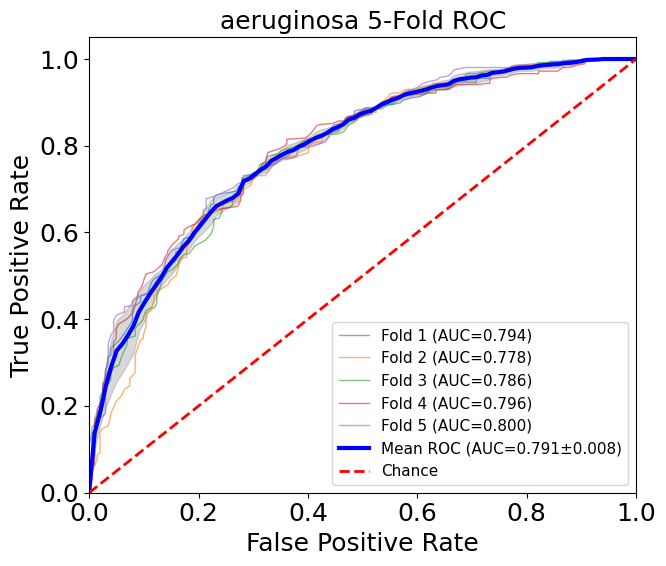

In [10]:
# ======================
# 五折ROC + 平均 + ±1SD阴影
# ======================
mean_fpr = np.linspace(0,1,100)
tprs = []
aucs = []
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.size": 18,          # 全局字体
    "axes.titlesize": 18,     # 标题
    "axes.labelsize": 18,     # 坐标轴标签
    "xtick.labelsize": 18,    # x刻度
    "ytick.labelsize": 18,    # y刻度
    "legend.fontsize": 11
})

plt.figure(figsize=(7,6))

for i, (train_idx,test_idx) in enumerate(cv.split(X,y),1):
    clf.fit(X[train_idx], y[train_idx])
    prob = clf.predict_proba(X[test_idx])[:,1]
    fpr, tpr, _ = roc_curve(y[test_idx], prob)
    roc_auc = auc(fpr, tpr)
    aucs.append(roc_auc)
    interp_tpr = np.interp(mean_fpr, fpr, tpr)
    interp_tpr[0] = 0
    tprs.append(interp_tpr)
    plt.plot(fpr, tpr, lw=1, alpha=0.6, label=f"Fold {i} (AUC={roc_auc:.3f})")

# 平均 + ±1SD
mean_tpr = np.mean(tprs, axis=0)
mean_tpr[-1] = 1.0
std_tpr = np.std(tprs, axis=0)
mean_auc = auc(mean_fpr, mean_tpr)
std_auc = np.std(aucs)

plt.plot(mean_fpr, mean_tpr, color='b', lw=3,
         label=f"Mean ROC (AUC={mean_auc:.3f}±{std_auc:.3f})")
plt.fill_between(mean_fpr,
                 mean_tpr - std_tpr,
                 mean_tpr + std_tpr,
                 color='grey', alpha=0.3)

# Chance line
plt.plot([0,1], [0,1], 'r--', lw=2, label="Chance")

plt.xlim([0,1])
plt.ylim([0,1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"{bac} 5-Fold ROC")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"{bac}_5fold_ROC.svg", dpi=600, bbox_inches="tight")
plt.show()

# 新数据测试 

In [ ]:
import torch
import pandas as pd
import numpy as np
import joblib
from Bio import SeqIO
from torch.utils.data import DataLoader

# ==========================================
# 参数
# ==========================================
fasta_file = "potential_amp_senior.fasta"
model_path = bac + "_best_rf_classifier.pkl"

# ==========================================
# 1. 读取序列ID和序列
# ==========================================
seq_ids = []
seqs = []

for record in SeqIO.parse(fasta_file, "fasta"):
    seq_ids.append(record.id)
    seqs.append(str(record.seq))

print("Number of sequences:", len(seq_ids))

# ==========================================
# 2. 读取特征
# ==========================================
X_esm = load_test_data_h5(
    "../../esm_embedding/potential_amp_senior.h5"
)

X_macrel = pd.read_csv(
    "../../macrel_embedding/potential_amp_senior.csv",
    index_col=0
).values

X_textcnn = pd.read_csv(
    "../../textcnn_convert/potential_amp_senior.csv",
    index_col=0
).values

print("ESM:", X_esm.shape)
print("Macrel:", X_macrel.shape)
print("TextCNN:", X_textcnn.shape)

# ==========================================
# 3. 转Tensor
# ==========================================
raw_X_new = [
    torch.tensor(X_macrel, dtype=torch.float32),
    torch.tensor(X_textcnn, dtype=torch.long),
    torch.tensor(X_esm, dtype=torch.float32)
]

# ==========================================
# 4. 与训练时完全一致的预处理
# ==========================================
X_list_train, X_list_val, X_new_list = preprocess_features(
    raw_X_train,
    raw_X_val,
    raw_X_new
)

# ==========================================
# 5. MOE提取特征
# ==========================================
new_dataset = TupleTestDataset(X_new_list)

new_loader = DataLoader(
    new_dataset,
    batch_size=1,
    shuffle=False,
    pin_memory=True
)

X_new_moe_output = moe_output_get(
    model,
    new_loader,
    device
)

# ==========================================
# 6. 加载RF模型
# ==========================================
rf_model = joblib.load(model_path)

print("Loaded model:", model_path)

# ==========================================
# 7. 预测
# ==========================================
pred_label = rf_model.predict(
    X_new_moe_output
)

pred_prob = rf_model.predict_proba(
    X_new_moe_output
)[:, 1]

# ==========================================
# 8. 保存结果
# ==========================================
result = pd.DataFrame({
    "Sequence_ID": seq_ids,
    "Sequence": seqs,
    "Prediction": pred_label,
    "Probability": pred_prob
})

result = result.sort_values(
    "Probability",
    ascending=False
)

output_file = bac + "_potential_amp_prediction.csv"

result.to_csv(
    output_file,
    index=False
)

print(result.head())

print("\nPrediction summary")
print("MIC ≤ 32 :", (pred_label == 1).sum())
print("MIC > 32 :", (pred_label == 0).sum())

print("\nSaved to:")
print(output_file)

# 输出最终高质量抗菌肽

In [3]:
import pandas as pd

# =========================
# 1. 读取文件
# =========================
coli = pd.read_csv("coli_potential_amp_prediction.csv")
aureus = pd.read_csv("aureus_potential_amp_prediction.csv")
aeruginosa = pd.read_csv("aeruginosa_potential_amp_prediction.csv")

# =========================
# 2. 筛选 Prediction == 1
# =========================
coli_set = set(coli[coli["Prediction"] == 1]["Sequence_ID"])
aureus_set = set(aureus[aureus["Prediction"] == 1]["Sequence_ID"])
aeruginosa_set = set(aeruginosa[aeruginosa["Prediction"] == 1]["Sequence_ID"])

# =========================
# 3. 取交集
# =========================
common_ids = coli_set & aureus_set & aeruginosa_set

print("Intersection size:", len(common_ids))

# =========================
# 4. 提取序列（从任意一个文件取 Sequence）
# =========================
all_data = pd.concat([coli, aureus, aeruginosa], ignore_index=True)

id_to_seq = dict(zip(all_data["Sequence_ID"], all_data["Sequence"]))

# =========================
# 5. 写 FASTA
# =========================
output_fasta = "high_quality_amp.fasta"

with open(output_fasta, "w") as f:
    for i in common_ids:
        seq = id_to_seq.get(i)
        if seq is None:
            continue
        f.write(f">{i}\n{seq}\n")

print("Saved to:", output_fasta)

Intersection size: 13221
Saved to: high_quality_amp.fasta


In [4]:
from Bio import SeqIO

# =========================
# 1. 查询肽段
# =========================
queries = [
    "ILRRWRRILKKIF",
    "IFKGLHRILLRLF",
    "ILGSGWLLKILKRL",
    "ILRYARRWTKLWLK",
    "IAISLKARWKLL",
    "IFKGLHRILLRFF",
    "ILRGIRTFVRWLFK",
    "IKLAKRLFVKLAKW",
    "ILLFGKIRIRLKL",
    "IVIAISLKARWKLLFGKK"
]

fasta_file = "high_quality_amp.fasta"

# =========================
# 2. 读取FASTA
# =========================
records = list(SeqIO.parse(fasta_file, "fasta"))

# =========================
# 3. 检索
# =========================
results = []

for q in queries:
    hit = False
    for rec in records:
        if q in str(rec.seq):
            results.append({
                "query": q,
                "hit_id": rec.id,
                "hit_seq": str(rec.seq)
            })
            hit = True
    if not hit:
        results.append({
            "query": q,
            "hit_id": None,
            "hit_seq": None
        })

# =========================
# 4. 输出结果
# =========================
for r in results:
    if r["hit_id"]:
        print(f"[FOUND] {r['query']} -> {r['hit_id']}")
    else:
        print(f"[NOT FOUND] {r['query']}")

[FOUND] ILRRWRRILKKIF -> MGYG000011844_59_14&#&17218&#&17418&#&1&#&ID=59_14;partial=00;start_type=ATG;rbs_motif=GGA/GAG/AGG;rbs_spacer=11-12bp;gc_cont=0.468,
[FOUND] IFKGLHRILLRLF -> MGYG000024518_81_5&#&4660&#&4863&#&-1&#&ID=81_5;partial=00;start_type=ATG;rbs_motif=GGA/GAG/AGG;rbs_spacer=3-4bp;gc_cont=0.466
[NOT FOUND] ILGSGWLLKILKRL
[FOUND] ILRYARRWTKLWLK -> MGYG000108579_15_19&#&18868&#&19071&#&-1&#&ID=15_19;partial=00;start_type=ATG;rbs_motif=GGAG/GAGG;rbs_spacer=5-10bp;gc_cont=0.500
[FOUND] IAISLKARWKLL -> MGYG000002945_30_29&#&24843&#&25127&#&1&#&ID=30_29;partial=00;start_type=ATG;rbs_motif=GGA/GAG/AGG;rbs_spacer=5-10bp;gc_cont=0.375,
[FOUND] IFKGLHRILLRFF -> MGYG000070033_119_10&#&8352&#&8555&#&-1&#&ID=119_10;partial=00;start_type=ATG;rbs_motif=GGA/GAG/AGG;rbs_spacer=3-4bp;gc_cont=0.441,
[FOUND] ILRGIRTFVRWLFK -> MGYG000107923_115_12&#&12312&#&12386&#&1&#&ID=115_12;partial=00;start_type=ATG;rbs_motif=AGGA;rbs_spacer=5-10bp;gc_cont=0.480
[FOUND] IKLAKRLFVKLAKW -> MGYG000235625_17